# 1. Khai báo thư viện và Đọc dữ liệu

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Tắt các thông báo cảnh báo
warnings.filterwarnings('ignore')

# Thiết lập phong cách biểu đồ và font chữ tiếng Việt
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'sans-serif' 

# Đọc dữ liệu
df_shop = pd.read_csv('../../data/preprocessed/shop_cleaned.csv')
display(df_shop.head())
display(df_shop.info())

,Shop URL,Seller ID,Loại cửa hàng,Followers,Đánh giá người bán,Danh mục chính,Số năm tham gia,Giao đúng hẹn,Tỷ lệ hủy đơn,Tỷ lệ phản hồi chat,Tên shop
0,https://www.lazada.vn/shop/oqrz1tvi/?path=prof...,2.009840e+11,Shop Thường,55.0,0.93,Beauty,0.75,0.98,NaN,0.8333,AuraBelle
1,https://www.lazada.vn/shop/laikou-selection/?p...,2.005483e+11,Shop Thường,201.0,0.98,Beauty,2.00,1.00,NaN,NaN,LAIKOU.Selection
2,https://www.lazada.vn/shop/on-moon/?path=profi...,2.001644e+11,Shop Thường,18894.0,0.96,Beauty,5.00,0.97,0.03,0.2000,On Moon
3,https://www.lazada.vn/shop/ddddvn-selection/?p...,2.005228e+11,Shop Thường,1505.0,0.98,Kitchenware & Tableware,2.00,0.98,NaN,1.0000,ddddVN.Selection
4,https://www.lazada.vn/shop/shopdep24h-chuyen-h...,1.000442e+09,Shop Thường,21377.0,0.99,Beauty,6.00,1.00,NaN,0.5000,Shopđẹp24h chuyên hàng chính hãng


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1980 entries, 0 to 1979
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Shop URL             1980 non-null   object 
 1   Seller ID            1952 non-null   float64
 2   Loại cửa hàng        1980 non-null   object 
 3   Followers            1975 non-null   float64
 4   Đánh giá người bán   1960 non-null   float64
 5   Danh mục chính       1980 non-null   object 
 6   Số năm tham gia      1683 non-null   float64
 7   Giao đúng hẹn        1764 non-null   float64
 8   Tỷ lệ hủy đơn        378 non-null    float64
 9   Tỷ lệ phản hồi chat  1320 non-null   float64
 10  Tên shop             1913 non-null   object 
dtypes: float64(7), object(4)
memory usage: 170.3+ KB


None

# 2. Phân tích Dữ liệu thiếu (Missing Values)

,Missing Values,Percentage (%)
Tỷ lệ hủy đơn,1602,80.909091
Tỷ lệ phản hồi chat,660,33.333333
Số năm tham gia,297,15.000000
Giao đúng hẹn,216,10.909091
Tên shop,67,3.383838
Seller ID,28,1.414141
Đánh giá người bán,20,1.010101
Followers,5,0.252525


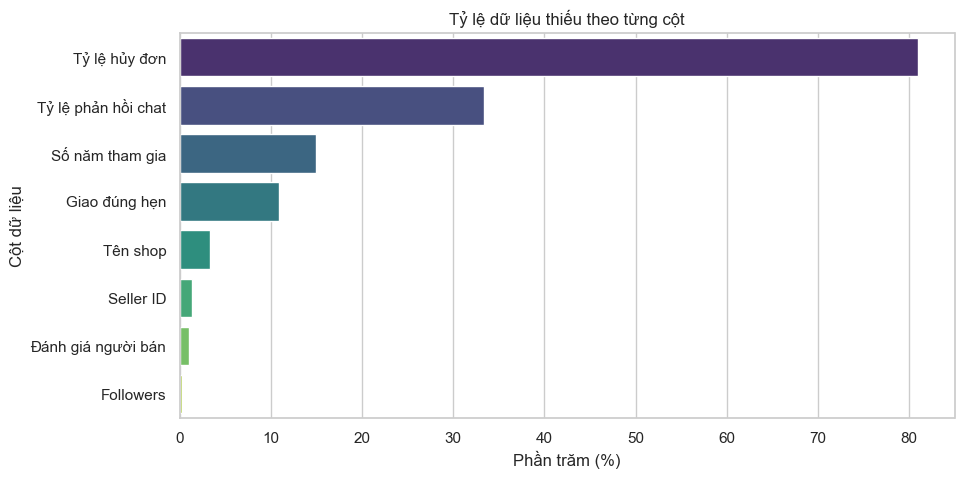

In [2]:
# Tính toán tỷ lệ dữ liệu thiếu
missing_values = df_shop.isnull().sum()
missing_percent = (missing_values / len(df_shop)) * 100
missing_df = pd.DataFrame({'Missing Values': missing_values, 'Percentage (%)': missing_percent})
missing_df = missing_df[missing_df['Missing Values'] > 0].sort_values(by='Percentage (%)', ascending=False)
display(missing_df)

# Trực quan hóa dữ liệu thiếu
plt.figure(figsize=(10, 5))
sns.barplot(x=missing_df['Percentage (%)'], y=missing_df.index, palette='viridis')
plt.title('Tỷ lệ dữ liệu thiếu theo từng cột')
plt.xlabel('Phần trăm (%)')
plt.ylabel('Cột dữ liệu')
plt.show()

### Nhận xét về dữ liệu thiếu 

Có tổng cộng 8 cột chứa giá trị thiếu với mức độ phân bổ rất chênh lệch, từ cực thấp (0.25%) đến rất cao (hơn 80%).

1. **Tỷ lệ hủy đơn (80.91%)**: Đây là cột có tỷ lệ thiếu nghiêm trọng nhất. Thông thường trên các sàn TMĐT (như Lazada), nếu một shop làm việc tốt và không có đơn hàng nào bị hủy, hệ thống có thể để trống thông số này thay vì hiển thị là 0%.
2. **Tỷ lệ phản hồi chat (33.33%)**: Tỷ lệ thiếu ở mức trung bình cao. Nguyên nhân chủ yếu có thể xuất phát từ các shop mới lập, hoặc các shop ít hoạt động nên chưa cào đủ lượng tin nhắn để hệ thống tính toán tỷ lệ.
3. **Số năm tham gia (15.0%) & Giao đúng hẹn (10.91%)**: Tỷ lệ thiếu ở mức vừa phải. Đối với `Số năm tham gia`, dữ liệu bị khuyết chủ yếu do hệ thống nền tảng/web không hiển thị (thiếu) thông tin này đối với một số shop. Với `Giao đúng hẹn`, có thể do shop chưa phát sinh đủ nhiều giao dịch giao hàng.
4. **Tên shop (3.38%) & Seller ID (1.41%)**: Đây là các cột định danh (ID và Tên), tỷ lệ khuyết cực kỳ thấp nhưng lại có rủi ro về tính toàn vẹn thông tin (vì mọi shop đều cần ID để phân biệt).
5. **Đánh giá người bán (1.01%) & Followers (0.25%)**: Mức độ thiếu không đáng kể, có vẻ đại diện cho các trường hợp lỗi nhỏ hoặc thiếu sót ngẫu nhiên trong quá trình cào dữ liệu.

### Đề xuất hướng xử lý Tiền xử lý

Để đảm bảo tính khách quan của tập dữ liệu sau xử lý, quá trình điền dữ liệu khuyết sẽ được tiến hành như sau:

* **Tỷ lệ hủy đơn**: Điền bằng giá trị **`0`**. Giả định hợp lý nhất ở đây là giá trị null xuất hiện khi shop chưa từng bị hủy đơn hàng nào.
* **Tỷ lệ phản hồi chat**: Điền bằng giá trị **Trung vị (Median) tính theo từng nhóm Loại cửa hàng**. Cụ thể, các shop thuộc nhóm `LazMall` sẽ được điền bằng Median của nhóm LazMall, và các shop thuộc nhóm `Shop Thường` sẽ được điền bằng Median của nhóm Shop Thường.
* **Số năm tham gia**: Điền bằng **Trung vị (Median)**. Do đây là lỗi hiển thị thiếu từ phía website, việc lấp đầy bằng trung vị của sàn sẽ giúp giữ được phân phối tự nhiên nhất của tập dữ liệu.
* **Giao đúng hẹn**: Điền bằng **Trung vị (Median)** của cột để tránh làm sai lệch phân phối tỷ lệ giao hàng chung.
* **Đánh giá người bán & Followers**: Do lượng thiếu rất ít (<1%), sử dụng **Trung vị (Median)** để lấp đầy số liệu.
* **Tên shop**: Thuộc loại dữ liệu chuỗi (String/Text), điền bằng chuỗi **`"Unknown"`**.
* **Seller ID**: Để dữ liệu đồng nhất và dễ quản lý, ta sẽ **thiết lập lại toàn bộ Seller ID mới** cho tất cả các shop theo định dạng chuỗi tự tăng: `S0001, S0002, S0003,...`. Điều này vừa khắc phục lỗi thiếu ID, vừa giúp chuẩn hóa định dạng nhận diện sau này.

# 3. Tiền xử lý dữ liệu thiếu

In [3]:
# Tiền xử lý dữ liệu thiếu 
# 1. Tỷ lệ hủy đơn: Điền bằng 0
df_shop['Tỷ lệ hủy đơn'] = df_shop['Tỷ lệ hủy đơn'].fillna(0)

# 2. Tỷ lệ phản hồi chat: Điền bằng Median tính theo từng nhóm 'Loại cửa hàng'
df_shop['Tỷ lệ phản hồi chat'] = df_shop.groupby('Loại cửa hàng')['Tỷ lệ phản hồi chat'].transform(lambda x: x.fillna(x.median()))

# 3. Điền Median cho các cột số còn lại
numeric_cols_to_fillna = ['Số năm tham gia', 'Giao đúng hẹn', 'Đánh giá người bán', 'Followers']
for col in numeric_cols_to_fillna:
    df_shop[col] = df_shop[col].fillna(df_shop[col].median())

# 4. Tên shop: Điền bằng "Unknown"
df_shop['Tên shop'] = df_shop['Tên shop'].fillna("Unknown")

# 5. Seller ID: Reset toàn bộ thành định dạng S0001, S0002,...
# Tạo ra chuỗi từ 1 đến tổng số dòng (len(df_shop)), dùng zfill(4) để điền số 0 ở đầu
df_shop['Seller ID'] = [f"S{str(i).zfill(4)}" for i in range(1, len(df_shop) + 1)]

# Kiểm tra lại xem còn dữ liệu thiếu không
print("Kiểm tra lại dữ liệu thiếu:")
display(df_shop.isnull().sum())

# Xêm trước dữ liệu sau khi sửa Seller ID
display(df_shop[['Tên shop', 'Seller ID']].head())

# 6. Ghi dữ liệu đã tiền xử lý xuống file CSV
# index=False để không lưu cột chỉ số mặc định của Pandas
df_shop.to_csv('../../data/preprocess and eda/shop_cleaned.csv', index=False, encoding='utf-8-sig')

# Kiểm tra lại
print("✅ Đã lưu dữ liệu sau tiền xử lý vào file shop_cleaned.csv")
print("Kiểm tra lại dữ liệu thiếu:")
display(df_shop.isnull().sum())


Kiểm tra lại dữ liệu thiếu:


Shop URL               0
Seller ID              0
Loại cửa hàng          0
Followers              0
Đánh giá người bán     0
Danh mục chính         0
Số năm tham gia        0
Giao đúng hẹn          0
Tỷ lệ hủy đơn          0
Tỷ lệ phản hồi chat    0
Tên shop               0
dtype: int64

,Tên shop,Seller ID
0,AuraBelle,S0001
1,LAIKOU.Selection,S0002
2,On Moon,S0003
3,ddddVN.Selection,S0004
4,Shopđẹp24h chuyên hàng chính hãng,S0005


✅ Đã lưu dữ liệu sau tiền xử lý vào file shop_cleaned.csv
Kiểm tra lại dữ liệu thiếu:


Shop URL               0
Seller ID              0
Loại cửa hàng          0
Followers              0
Đánh giá người bán     0
Danh mục chính         0
Số năm tham gia        0
Giao đúng hẹn          0
Tỷ lệ hủy đơn          0
Tỷ lệ phản hồi chat    0
Tên shop               0
dtype: int64

# Mô Tả Tập Dữ Liệu Cửa Hàng Lazada - Sau Xử Lý Tiền Xử Lý

## Cấu Trúc Dữ Liệu

Tập dữ liệu bao gồm **1,980 cửa hàng (Sellers)** và **11 cột (Features)** được chia thành **3 nhóm chính**:

### Nhóm 1: Xác Định Cửa Hàng (Categorical)

| Cột | Mô Tả |
|-----|-------|
| **Seller ID** | Mã định danh duy nhất cho mỗi cửa hàng (ví dụ: S0001, S0002, ...) |
| **Tên shop** | Tên cửa hàng trên sàn Lazada |
| **Shop URL** | Đường dẫn trang cửa hàng trên Lazada |
| **Loại cửa hàng** | Phân loại loại chủ thể bán hàng (LazMall hoặc Shop Thường) |
| **Danh mục chính** | Ngành hàng chính mà cửa hàng người bán tập trung (ví dụ: Beauty, Women's Clothing, Men's Clothing,...) |

### Nhóm 2: Chỉ Số Hiệu Suất & Sức Khỏe Kinh Doanh (Numerical)

| Cột | Mô Tả |
|-----|-------|
| **Số năm tham gia** | Thời gian cửa hàng tham gia sàn Lazada (tính bằng năm) |
| **Followers** | Số lượng người theo dõi/khách hàng trung thành của cửa hàng |
| **Đánh giá người bán** | Mức đánh giá chung của cửa hàng từ khách hàng (từ 0 đến 1, ví dụ: 0.95 = 95%) |
| **Giao đúng hẹn** | Tỷ lệ phần trăm đơn hàng được giao đúng dự kiến (từ 0 đến 1, ví dụ: 0.98 = 98%) |
| **Tỷ lệ hủy đơn** | Tỷ lệ phần trăm đơn hàng bị hủy hoặc từ chối (từ 0 đến 1, ví dụ: 0.02 = 2%) |
| **Tỷ lệ phản hồi chat** | Tỷ lệ phần trăm cửa hàng phản hồi tin nhắn khách hàng kịp thời (từ 0 đến 1, ví dụ: 0.80 = 80%) |

### Giải Thích Thêm

- **Loại cửa hàng:**
  - **LazMall:** Shop ủy quyền/chính hãng do Lazada quản lý chặt, có tiêu chuẩn chất lượng nghiêm ngặt
  - **Shop Thường:** Nhà bán lẻ độc lập, tiểu thương với quy mô vừa và nhỏ
  
- **Đơn vị tỷ lệ:** Tất cả các chỉ số phần trăm được chuẩn hóa từ 0 đến 1 (ví dụ: 0.95 = 95%, 0.80 = 80%)

# 4. EDA - Khám phá các biến phân loại và liên tục

## 4.1. Biểu đồ đếm 'Loại cửa hàng'

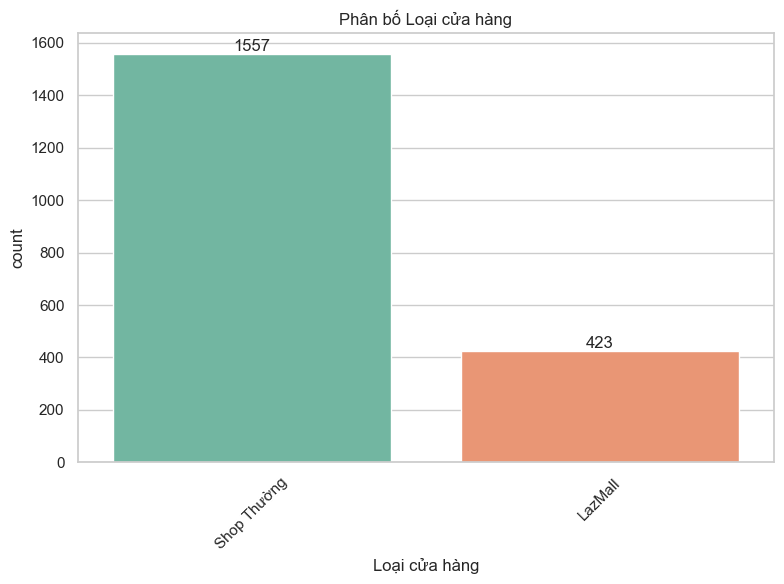

Số lượng cụ thể của từng loại cửa hàng:


Loại cửa hàng
Shop Thường    1557
LazMall         423
Name: count, dtype: int64

In [4]:
plt.figure(figsize=(8, 6))

# Vẽ biểu đồ đếm (Thêm hue và legend=False để tránh cảnh báo của thư viện mới)
ax = sns.countplot(data=df_shop, x='Loại cửa hàng', hue='Loại cửa hàng', palette='Set2', legend=False)
plt.title('Phân bố Loại cửa hàng')
plt.xticks(rotation=45)

# Thêm số lượng trực tiếp lên đỉnh các cột biểu đồ
for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

# Print ra số lượng cụ thể của từng nhóm
print("Số lượng cụ thể của từng loại cửa hàng:")
display(df_shop['Loại cửa hàng'].value_counts())

**Nhận xét (Insight) - Loại cửa hàng:**
*   **Thực trạng:** `Shop Thường` chiếm ưu thế tuyệt đối về mặt số lượng (1557 shop), gấp gần 4 lần số lượng cửa hàng `LazMall` (423 shop).
*   **Insight:** Sàn thương mại điện tử Lazada ở các nhóm ngành hàng đang khảo sát chủ yếu được duy trì bởi các nhà bán lẻ độc lập hoặc tiểu thương. Việc thu hút hoặc tối ưu hóa trải nghiệm cho nhóm `Shop Thường` là chìa khóa để giữ vững hệ sinh thái. Trong khi đó, `LazMall` dù ít về số lượng nhưng sẽ đóng vai trò là chỗ dựa niềm tin về chất lượng cho người tiêu dùng.

## 4.2. Phân bố 'Đánh giá người bán'


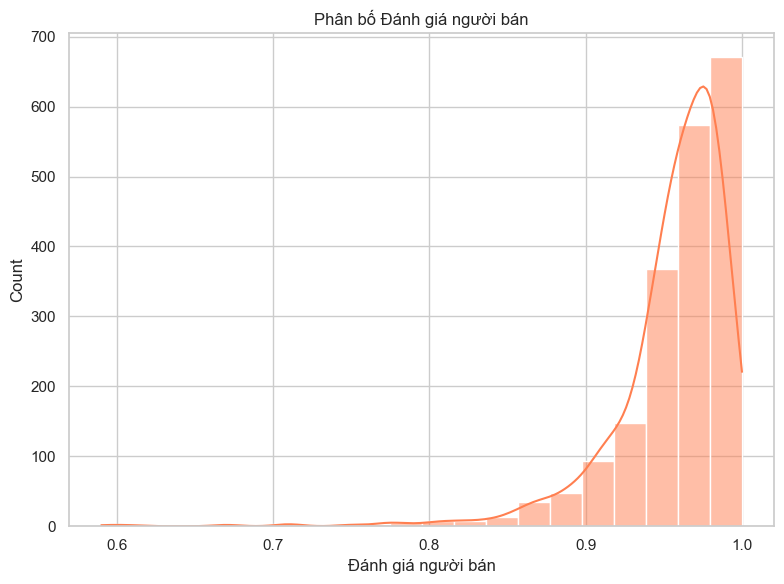

In [5]:
plt.figure(figsize=(8, 6))
sns.histplot(df_shop['Đánh giá người bán'].dropna(), bins=20, kde=True, color='coral')
plt.title('Phân bố Đánh giá người bán')
plt.tight_layout()
plt.show()

**Nhận xét (Insight) - Đánh giá người bán:**
*   **Thực trạng:** Biểu đồ phân phối lệch trái cực mạnh. Điểm đánh giá tập trung dày đặc ở dải từ $0.95$ đến $1.0$ (tức 95% - 100% hài lòng). Rất hiếm shop có điểm đánh giá dưới $0.8$.
*   **Insight:** Nhìn chung, mức độ hài lòng của khách hàng đối với các shop là rất cao. Mặt khác, tín hiệu này cũng cho thấy hệ thống đánh giá có thể đang bị "lạm phát" hoặc sàn có chính sách loại bỏ/ẩn đi những shop có điểm quá thấp. Khách hàng khi mua sắm sẽ rất nhạy cảm với các shop có điểm dưới trung bình ngành (khoảng $<0.9$), xem đó là rủi ro lớn.

## 4.3. Top 10 Danh mục chính về số lượng


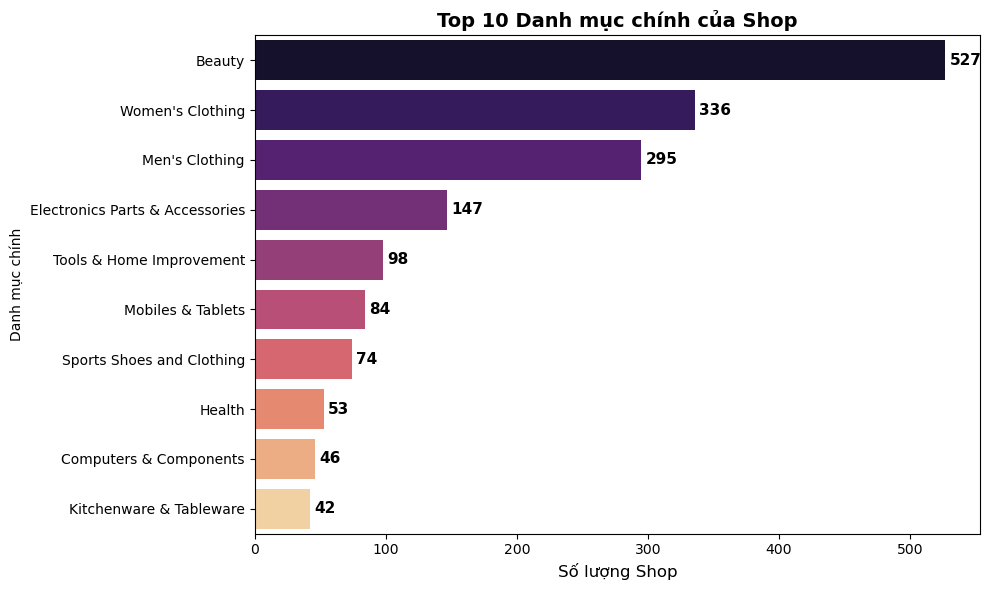


BẢNG CHI TIẾT - TOP 10 DANH MỤC CHÍNH
 1. Beauty                              |  527 shop
 2. Women's Clothing                    |  336 shop
 3. Men's Clothing                      |  295 shop
 4. Electronics Parts & Accessories     |  147 shop
 5. Tools & Home Improvement            |   98 shop
 6. Mobiles & Tablets                   |   84 shop
 7. Sports Shoes and Clothing           |   74 shop
 8. Health                              |   53 shop
 9. Computers & Components              |   46 shop
10. Kitchenware & Tableware             |   42 shop


In [8]:
plt.figure(figsize=(10, 6))
top_categories = df_shop['Danh mục chính'].value_counts().nlargest(10)

ax = sns.barplot(x=top_categories.values, y=top_categories.index, hue=top_categories.index, palette='magma', legend=False)

plt.title('Top 10 Danh mục chính của Shop', fontsize=14, fontweight='bold')
plt.xlabel('Số lượng Shop', fontsize=12)

# Thêm số lượng hiển thị ở cuối mỗi thanh ngang
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=11, weight='bold')

plt.tight_layout()
plt.show()

# In bảng dưới biểu đồ
print("\n" + "="*50)
print("BẢNG CHI TIẾT - TOP 10 DANH MỤC CHÍNH")
print("="*50)
for idx, (danh_muc, so_luong) in enumerate(top_categories.items(), 1):
    print(f"{idx:2d}. {danh_muc:35s} | {so_luong:4d} shop")
print("="*50)

**Nhận xét (Insight) - Top 10 Danh mục chính:**
*   **Thực trạng:** Nhóm `Beauty` (Làm đẹp) dẫn đầu áp đảo với 527 cửa hàng. Bám sát sau đó là nhóm ngành thời trang: `Women's Clothing` (336) và `Men's Clothing` (295).
*   **Insight:** Tập dữ liệu phản ánh rõ nét sức hút của nhóm ngành "Tiêu dùng thiết yếu cá nhân" (Sắc đẹp & Thời trang) trong giới bán lẻ trực tuyến tại Việt Nam. Đây là những ngành hàng có rào cản gia nhập thấp, dễ nhập nguồn hàng và có biên độ xoay vòng vốn nhanh, thu hút một lượng khổng lồ các shop tham gia cạnh tranh.

# 4.4. Phân bố 'Followers'

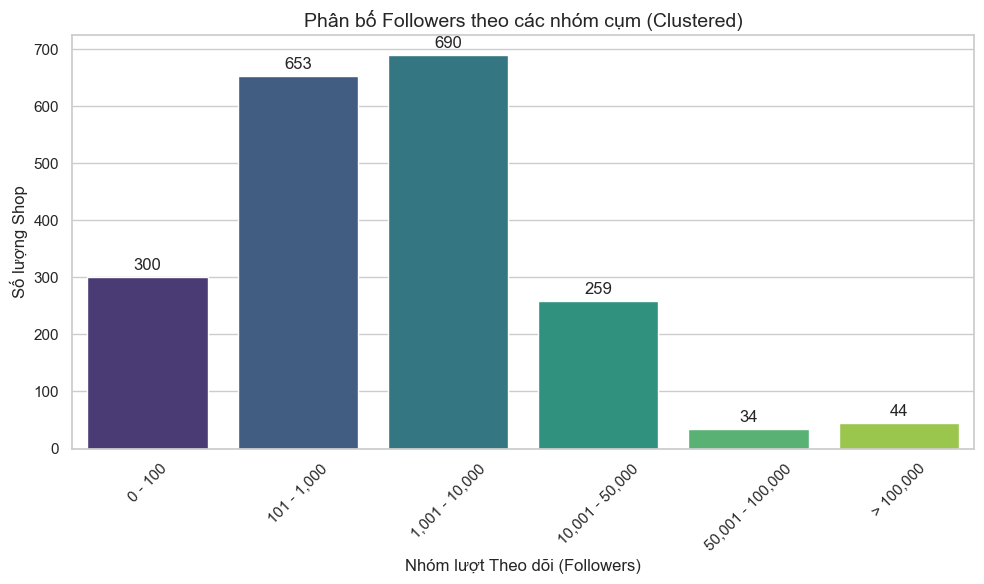

Bảng thống kê số lượng shop theo cụm Followers:


,Số lượng Shop,count
0,0 - 100,300
1,"101 - 1,000",653
2,"1,001 - 10,000",690
3,"10,001 - 50,000",259
4,"50,001 - 100,000",34
5,"> 100,000",44


In [7]:
plt.figure(figsize=(10, 6))

# Định nghĩa các mốc phân cụm (bins) và nhãn tương ứng
bins = [-1, 100, 1000, 10000, 50000, 100000, np.inf]
labels = ['0 - 100', '101 - 1,000', '1,001 - 10,000', '10,001 - 50,000', '50,001 - 100,000', '> 100,000']

# Phân cụm dữ liệu Followers
followers_clustered = pd.cut(df_shop['Followers'].dropna(), bins=bins, labels=labels)

# Tính toán số lượng cho từng cụm và vẽ barplot
followers_counts = followers_clustered.value_counts().reindex(labels)

ax = sns.barplot(x=followers_counts.index, y=followers_counts.values, hue=followers_counts.index, palette='viridis', legend=False)

# Cấu hình biểu đồ
plt.title('Phân bố Followers theo các nhóm cụm (Clustered)', fontsize=14)
plt.xlabel('Nhóm lượt Theo dõi (Followers)', fontsize=12)
plt.ylabel('Số lượng Shop', fontsize=12)
plt.xticks(rotation=45)

# Thêm số liệu trực tiếp trên đầu mỗi cột
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

# Print ra bảng thống kê chi tiết
print("Bảng thống kê số lượng shop theo cụm Followers:")
display(followers_counts.reset_index().rename(columns={'index': 'Nhóm Followers', 'Followers': 'Số lượng Shop'}))

**Nhận xét (Insight) - Phân bố Followers:**
*   **Thực trạng:** Phần lớn các shop rơi vào nhóm quy mô "Nhỏ" và "Siêu nhỏ". Có $690$ shop ở dải $1,001 - 10,000$ follow và $653$ shop ở dải $101 - 1,000$ follow. Số lượng shop cán mốc khổng lồ ($>100,000$ follow) chỉ đếm trên đầu ngón tay (44 shop).
*   **Insight:** Đây là biểu hiện của quy luật trong thương mại điện tử. Một tập nhỏ các shop lớn sở hữu lượng fan áp đảo toàn sàn. Điều này đòi hỏi các shop mới (nhỏ) phải dùng các thủ thuật như flash-sale, giảm giá sâu để kích cầu chứ không thể dựa vào lượng khách hàng tự nhiên.

# 4.5. Ma trận tương quan các biến số

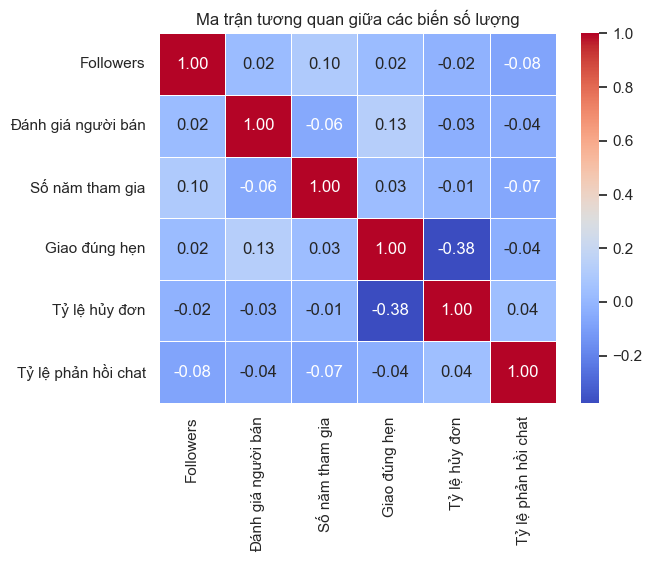

In [8]:
# Tính toán ma trận tương quan cho các cột dạng số
corr_matrix = df_shop.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Ma trận tương quan giữa các biến số lượng')
plt.show()

**Nhận xét (Insight) - Ma trận tương quan các biến số:**
*   **Thực trạng:** Nhìn tổng thể, bức tranh ma trận có màu nhạt (thiên về 0), chứng tỏ mạng lưới các biến số kỹ thuật của shop không có sự ràng buộc tuyến tính (linear correlation) mạnh mẽ với nhau. 
    *   Điểm sáng duy nhất và đậm nét nhất là cặp `Giao đúng hẹn` và `Tỷ lệ hủy đơn` (-0.38), khẳng định sự tương quan nghịch rõ rệt (đã phân tích ở phần trên).
    *   Bất ngờ là các yếu tố như `Số năm tham gia` gần như không ảnh hưởng đến lượng `Followers` (chỉ ở mức 0.10) hay `Đánh giá người bán` (-0.06). Tương tự, `Tỷ lệ phản hồi chat` không tác động nhiều đến các chỉ số còn lại.
*   **Insight:** Trái với suy nghĩ thông thường rằng tuổi đời của một shop trên sàn TMĐT không giúp ích nhiều cho việc tăng điểm đánh giá hay gom khách hàng trung thành (Followers). Thành công của shop không đến từ các thông số hoạt động bề nổi (như trực chat nhanh hay lập shop từ lâu) mà đến từ **chất lượng cốt lõi của sản phẩm, giá cả và các chiến thuật marketing/khuyến mãi thực tế**. Chỉ số duy nhất gây hệ lụy trực tiếp đến tình trạng kinh doanh là năng lực vận chuyển (giao đúng hẹn liên quan mật thiết đến tỷ lệ hủy).

# 4.6. Mối quan hệ giữa Giao đúng hẹn và Tỷ lệ hủy đơn

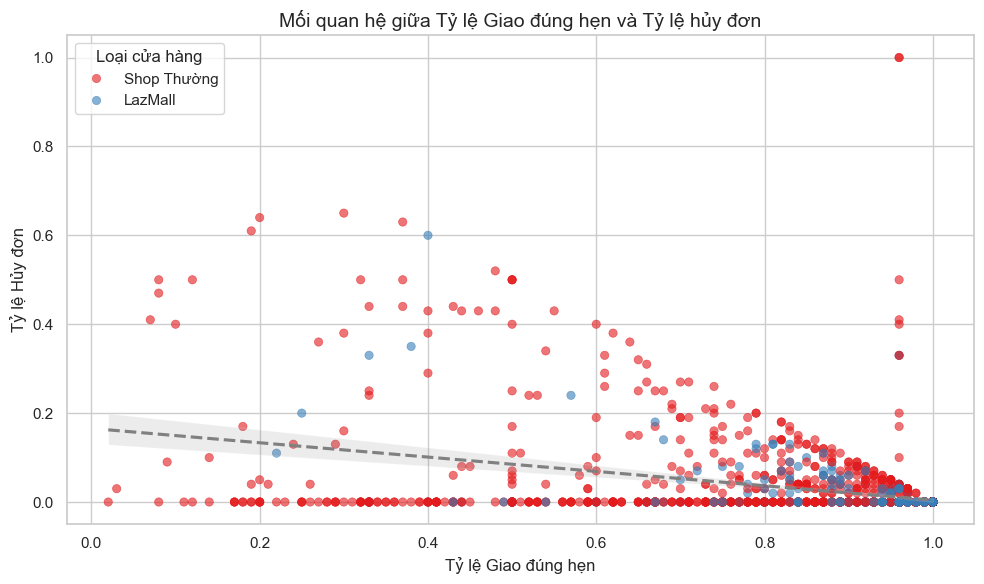

Hệ số tương quan (Pearson): -0.3766
-> Tương quan nghịch: Tỷ lệ giao đúng hẹn càng cao thì tỷ lệ hủy đơn có xu hướng càng thấp.


In [9]:
## 4.6. Mối quan hệ giữa Giao đúng hẹn và Tỷ lệ hủy đơn

plt.figure(figsize=(10, 6))

# Vẽ biểu đồ phân tán (scatter plot) kết hợp phân loại theo 'Loại cửa hàng'
sns.scatterplot(
    data=df_shop, 
    x='Giao đúng hẹn', 
    y='Tỷ lệ hủy đơn', 
    hue='Loại cửa hàng', 
    alpha=0.6, 
    palette='Set1',
    edgecolor=None
)

# Thêm đường xu hướng (regression line) chung cho toàn bộ dữ liệu để nhìn rõ tương quan
sns.regplot(
    data=df_shop, 
    x='Giao đúng hẹn', 
    y='Tỷ lệ hủy đơn', 
    scatter=False, 
    color='gray', 
    line_kws={"linestyle": "dashed"}
)

plt.title('Mối quan hệ giữa Tỷ lệ Giao đúng hẹn và Tỷ lệ hủy đơn', fontsize=14)
plt.xlabel('Tỷ lệ Giao đúng hẹn', fontsize=12)
plt.ylabel('Tỷ lệ Hủy đơn', fontsize=12)
plt.tight_layout()
plt.show()

# Tính và in ra hệ số tương quan (Pearson)
corr_value = df_shop['Giao đúng hẹn'].corr(df_shop['Tỷ lệ hủy đơn'])
print(f"Hệ số tương quan (Pearson): {corr_value:.4f}")
if corr_value < 0:
    print("-> Tương quan nghịch: Tỷ lệ giao đúng hẹn càng cao thì tỷ lệ hủy đơn có xu hướng càng thấp.")
else:
    print("-> Tương quan thuận: Hai biến có xu hướng thay đổi cùng chiều (ít khi xảy ra trong thực tế).")

**Nhận xét (Insight) - Giao đúng hẹn vs Tỷ lệ hủy đơn:**
*   **Thực trạng:** Đường xướng hướng (Regression line) chúi xuống và hệ số Pearson âm (-0.380) khẳng định có mối tương quan nghịch rõ rệt: Tỷ lệ `Giao đúng hẹn` hướng về 1.0 (100%) thì `Tỷ lệ hủy đơn` co cụm sát vùng $0.0$.
*   **Điểm đáng lưu ý (LazMall vs Shop Thường):** Có thể thấy mảng chấm xanh dương (LazMall) nằm co cụm chặt chẽ ở góc cực phải (Giao đúng hẹn gần ~1.0 và Hủy đơn ~0.0). Trong khi đó, các chấm đỏ (Shop Thường) nằm rải rác toàn bảng, thậm chí vươn lên tới tỷ lệ hủy giao dịch cao >50%.
*   **Insight:** Giao hàng đúng hạn là nhân tố tiên quyết để giảm tỷ lệ hủy đơn (giữ chân khách hàng). Nhóm LazMall chứng minh sự uy tín, quản lý kho bãi tốt hơn hẳn mặt bằng chung các Shop thường.